Task 2: CNN - CIFAR-10 Image Classification
Task:
Build a CNN model to classify images into 10 different object categories such as airplane, automobile, bird, cat, dog, frog, horse, ship, and truck.
Dataset Library:
sklearn.datasets.fetch_olivetti_faces
Task:
 Build a CNN model to recognize different people from their facial images.
Steps:
1.Load the Olivetti Faces dataset.
2.Display sample face images.
3.Check the image dimensions and number of classes.
4.Normalize the pixel values.
5.Reshape the images for CNN input.
6.Split the dataset into training and testing sets.
7.Build a CNN using Conv2D and MaxPooling2D layers.
8.Add Flatten and Dense layers.
9.Use ReLU activation in hidden layers.
10.Use Softmax in the output layer.
11.Train the CNN model.
12.Evaluate the model on test data.
13.Display sample images with predicted and actual person labels.


In [1]:
# Import Libraries required

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
 

In [2]:
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential

1.Load the Olivetti Faces dataset.

In [3]:
from sklearn.datasets import fetch_olivetti_faces

In [4]:
df = fetch_olivetti_faces()

In [5]:
# Dataset loaded 
X= df.images
y= df.target

In [6]:
print("Number of Images:" ,X.shape[0])
print("Image Shape:", X.shape[1:])
print("NUmber of Classes:",len(np.unique(y)))

Number of Images: 400
Image Shape: (64, 64)
NUmber of Classes: 40


2.Display sample face images.

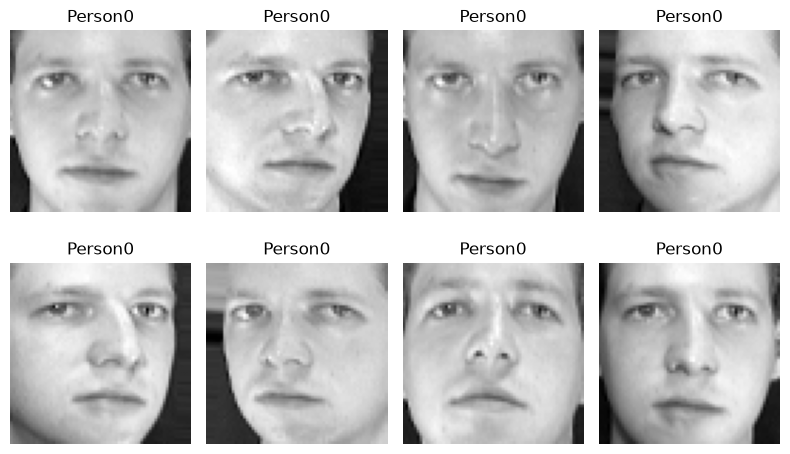

In [7]:
# Display sample face images
plt.figure(figsize=(8,5))

for i in range(8):
    plt.subplot(2,4,i + 1)
    plt.imshow(X[i],
cmap="grey")
    plt.title("Person" + str(y[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
# 3.Check the image dimensions and number of classes.

In [9]:
print("Number of Images:" ,X.shape[0])
print("Image height:", X.shape[1])
print("Image Width:",X.shape[2])
print("NUmber of Classes:",len(np.unique(y)))


Number of Images: 400
Image height: 64
Image Width: 64
NUmber of Classes: 40


In [10]:
# 4.Normalize the pixel values.

In [11]:
X = X.astype("float32")/255.0
print("Minimum pixel value:", X.min())
print("Maximum Pixel Value:", X.max())

Minimum pixel value: 0.0
Maximum Pixel Value: 0.003921569


In [12]:
# Reshape the images for CNN input.
X = X. reshape(-1,64,64,1)
print("New image Shape:", X.shape)

New image Shape: (400, 64, 64, 1)


In [13]:
# 6.Split the dataset into training and testing sets.
X_train, X_test, y_train,y_test = train_test_split(X,y,test_size=0.2,
                                                   random_state=42,
                                                   stratify=y)
print("Training images:", X_train.shape[0])
print("Testing images:", X_test.shape[0])


Training images: 320
Testing images: 80


In [18]:
# 7.Build a CNN using Conv2D and MaxPooling2D layers.

model = Sequential()

# first convolution
model.add(
    Conv2D(16,(3,3),
    activation = 'relu',
    input_shape=(64,64,1))
)

model.add(MaxPooling2D(2,2))

# Second Convolution Layer
model.add(Conv2D(32,(3,3),
          activation = 'relu'))
model.add(MaxPooling2D(2,2))



C:\Users\ADMIN\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:
# 8.Add Flatten and Dense layers.
model.add(Flatten())
model.add(Dense(64,activation='relu'))

model.add(Dense(40,activation='softmax'))



In [21]:
# 9.Use ReLU activation in hidden layers.
Conv2D(16,(3,3),activation='relu')
Conv2D(32,(3,3),activation='relu')
Dense(64, activation='relu')


<Dense name=dense_3, built=False>

In [22]:
# 10.Use Softmax in the output layer.
model.add(Dense(40,activation='softmax'))


In [23]:
#11.Train the CNN model.
#compile
model.compile(optimizer='adam',loss="sparse_categorical_crossentropy",
              metrics=['accuracy']
              )


In [24]:
#CNN architecture
model.summary()

#Train
hist =model.fit(X_train,
                y_train,
                epochs=10,
                batch_size=16,
                verbose=1)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 62, 62, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 29, 29, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       401,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 40)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 40)             │         1,640 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 414,672 (1.58 MB)

 Trainable params: 414,672 (1.58 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 77ms/step - accuracy: 0.0250 - loss: 3.6907
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.0250 - loss: 3.6900
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.0250 - loss: 3.6898
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 85ms/step - accuracy: 0.0250 - loss: 3.6900
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - accuracy: 0.0250 - loss: 3.6900
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - accuracy: 0.0250 - loss: 3.6898
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 81ms/step - accuracy: 0.0250 - loss: 3.6899
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.0250 - loss: 3.6899
Epoch 9/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step - accuracy: 0.0250 - loss: 3.6898
Epoch 10/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.0250 - loss: 3.6896


In [27]:
# 12.Evaluate the model on test data.
test_loss,test_acc =model.evaluate(X_test,
                                   y_test,verbose=0)
print("test_loss:", test_loss)
print("Test Accuracy:",test_acc)


test_loss: 3.689074754714966
Test Accuracy: 0.02500000037252903


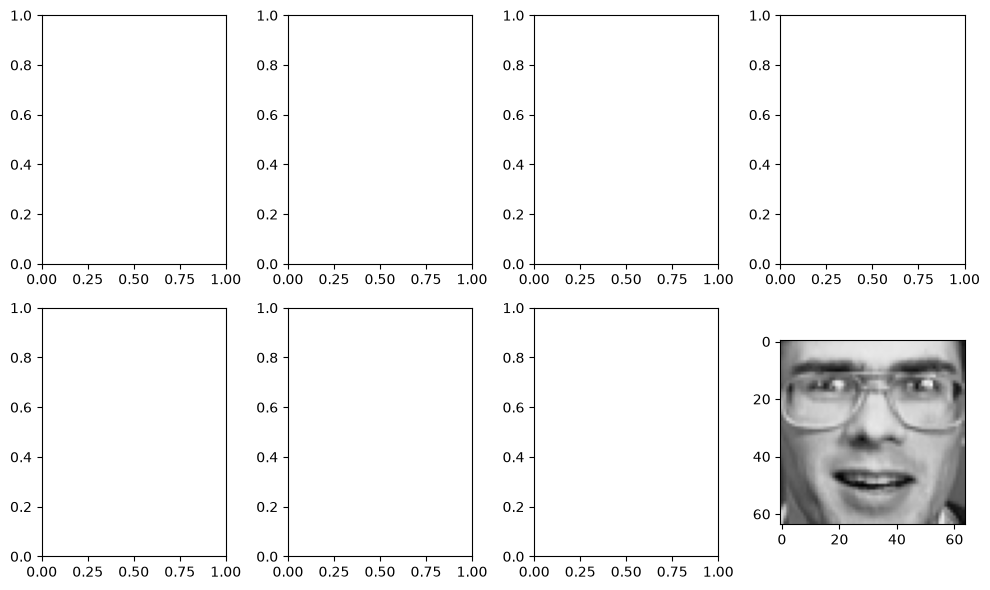

In [30]:
# 13.Display sample images with predicted and actual person labels.
plt.figure(figsize=(10,6))

for i in range(8):
    plt.subplot(2,4,i+1)

plt.imshow(X_test[i].squeeze(),cmap='grey')

plt.tight_layout()
plt.show()